# Face Emotion Detector
Goal: find every face in an image or video frame and say which **facial expression** it shows (anger, contempt, disgust, fear, happiness, neutral, sadness, surprise).

The system is two pretrained networks chained together:
1. **YOLOv8n-face** — a small YOLO detector trained to find faces,
2. **HSEmotion `enet_b0_8_best_afew`** — an EfficientNet-B0 classifier for 8 emotions (trained on AffectNet, fine-tuned on AFEW).

The notebook walks through generic object detection, face detection, face cropping, emotion scores, the combined `analyze(frame)` pipeline and a speed test. The live webcam loop is in `webcam.py`.

In [1]:
import time, urllib.request, warnings
warnings.filterwarnings('ignore')
from pathlib import Path
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from ultralytics import YOLO
from hsemotion_onnx.facial_emotions import HSEmotionRecognizer
from skimage import data as skdata

DATA = Path('data'); DATA.mkdir(exist_ok=True)
ASSETS = 'https://raw.githubusercontent.com/ultralytics/ultralytics/main/ultralytics/assets/'
FACE_URL = 'https://github.com/akanametov/yolo-face/releases/download/1.0.0/yolov8n-face.pt'

def fetch(url, path):
    path = Path(path)
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    return str(path)

def show(*images, titles=None, size=6):
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size * 0.62))
    for i, (ax, im) in enumerate(zip(np.atleast_1d(axes), images)):
        ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax.axis('off')
        if titles: ax.set_title(titles[i])
    plt.tight_layout(); plt.show()

zidane = cv2.imread(fetch(ASSETS + 'zidane.jpg', DATA / 'zidane.jpg'))
astronaut = cv2.cvtColor(skdata.astronaut(), cv2.COLOR_RGB2BGR)
print('zidane:', zidane.shape, ' astronaut:', astronaut.shape)

zidane: (720, 1280, 3)  astronaut: (512, 512, 3)


## 1. Generic object detection with YOLO11n
A COCO-pretrained YOLO11n finds 80 kinds of objects. It returns, per object, a box (`x1, y1, x2, y2` in pixels), a confidence and a class id.

In [2]:
yolo = YOLO(str(DATA / 'yolo11n.pt'))
r = yolo(zidane, verbose=False)[0]
pd.DataFrame({'class': [r.names[int(c)] for c in r.boxes.cls],
              'confidence': r.boxes.conf.numpy().round(2),
              'box (x1, y1, x2, y2)': r.boxes.xyxy.int().tolist()})

,class,confidence,"box (x1, y1, x2, y2)"
0,person,0.84,"[748, 41, 1148, 711]"
1,person,0.78,"[148, 203, 1125, 714]"
2,tie,0.45,"[361, 437, 524, 717]"


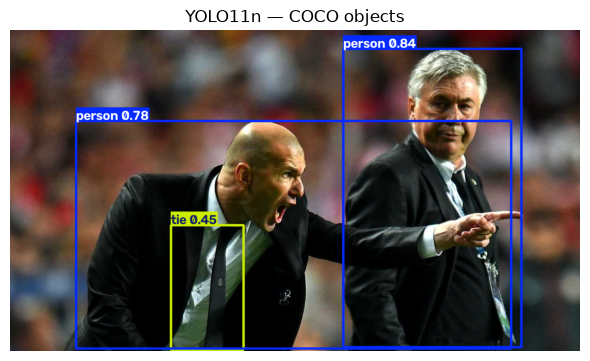

In [3]:
show(r.plot(), titles=['YOLO11n — COCO objects'])

It finds the two people and a tie, but COCO has no *face* class — for emotions we need a face detector.

## 2. Face detection with YOLOv8n-face
Same architecture, trained on WIDER FACE. It has a single class (`face`) and also predicts 5 facial landmarks (eyes, nose, mouth corners).

2 faces, classes: {0: 'face'}
[913, 92, 1055, 276] confidence 0.82
[542, 242, 663, 448] confidence 0.77


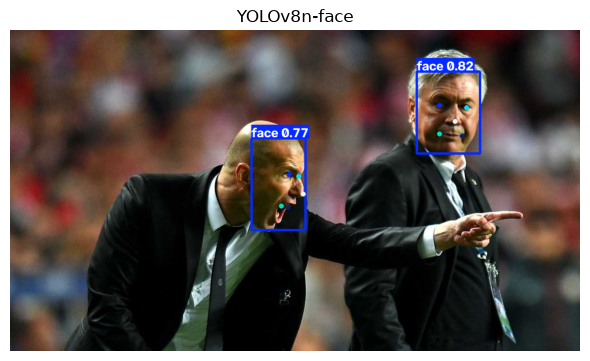

In [4]:
face_model = YOLO(fetch(FACE_URL, DATA / 'yolov8n-face.pt'))
r = face_model(zidane, verbose=False)[0]
print(len(r.boxes), 'faces, classes:', r.names)
for b, c in zip(r.boxes.xyxy.int().tolist(), r.boxes.conf.tolist()):
    print(b, f'confidence {c:.2f}')
show(r.plot(), titles=['YOLOv8n-face'])

## 3. Crop a face
A box is just array slicing: rows `y1:y2`, columns `x1:x2`.

face crop shape: (184, 142, 3)


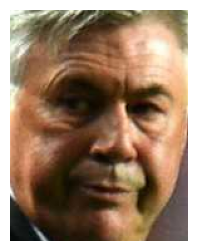

In [5]:
x1, y1, x2, y2 = r.boxes.xyxy[0].int().tolist()
face = zidane[y1:y2, x1:x2]
print('face crop shape:', face.shape)
plt.figure(figsize=(2.5, 3)); plt.imshow(cv2.cvtColor(face, cv2.COLOR_BGR2RGB)); plt.axis('off'); plt.show()

## 4. Emotion scores with HSEmotion
`HSEmotionRecognizer` resizes the RGB crop to 224×224, normalises it with ImageNet mean/std and returns a probability for each of the 8 emotions.

Predicted: Anger (30%)


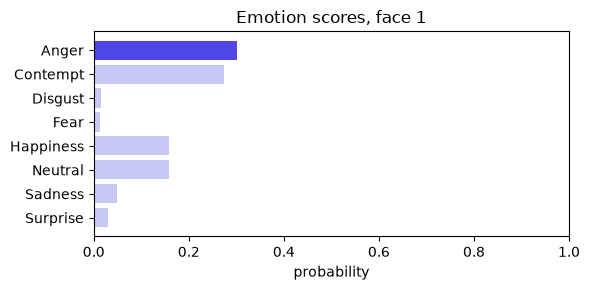

In [6]:
emo = HSEmotionRecognizer(model_name='enet_b0_8_best_afew')
EMOTIONS = list(emo.idx_to_class.values())
name, scores = emo.predict_emotions(cv2.cvtColor(face, cv2.COLOR_BGR2RGB), logits=False)
print(f'Predicted: {name} ({scores.max():.0%})')
plt.figure(figsize=(6, 3))
plt.barh(EMOTIONS, scores, color=['#4f46e5' if e == name else '#c7c9f5' for e in EMOTIONS])
plt.gca().invert_yaxis(); plt.xlabel('probability'); plt.xlim(0, 1); plt.title('Emotion scores, face 1')
plt.tight_layout(); plt.show()

## 5. One `analyze(frame)` pipeline
Detect faces → crop each → classify → draw box + label. The same function powers the webcam script.

zidane:    [('Anger', 0.3), ('Anger', 0.89)]
astronaut: [('Happiness', 1.0)]


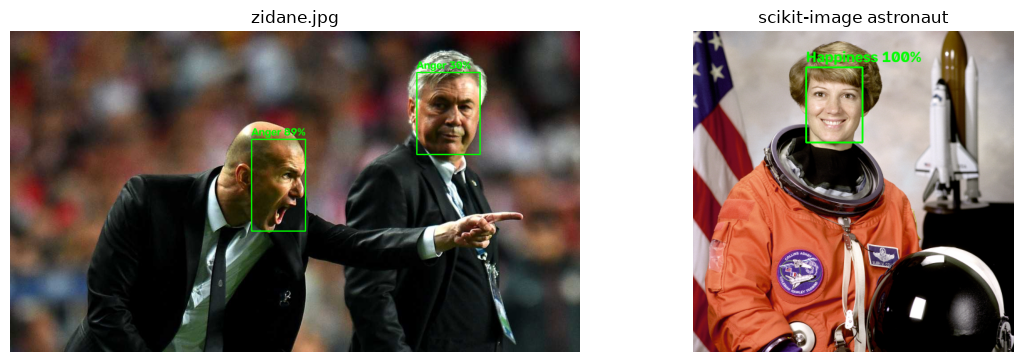

In [7]:
def analyze(frame, size=640):
    frame, found = frame.copy(), []
    r = face_model(frame, imgsz=size, verbose=False)[0]
    for x1, y1, x2, y2 in r.boxes.xyxy.int().tolist():
        if x2 <= x1 or y2 <= y1:
            continue
        rgb = cv2.cvtColor(frame[y1:y2, x1:x2], cv2.COLOR_BGR2RGB)
        name, scores = emo.predict_emotions(rgb, logits=False)
        found.append((name, round(float(scores.max()), 2)))
        cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(frame, f'{name} {scores.max():.0%}', (x1, max(y1 - 8, 16)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)
    return frame, found

out_z, found_z = analyze(zidane)
out_a, found_a = analyze(astronaut)
print('zidane:   ', found_z)
print('astronaut:', found_a)
show(out_z, out_a, titles=['zidane.jpg', 'scikit-image astronaut'])

The astronaut is confidently **happy**, and Zidane's shout is read as **anger** with high confidence. Ancelotti's raised-eyebrow look is ambiguous: anger and contempt get roughly a third of the probability each. That is a realistic picture of an 8-class expression model on real-world crops — clear expressions are easy, subtle ones are split between neighbouring classes.

## 6. Speed: 640 vs 320 input size
YOLO resizes every frame to the input size. A smaller input means fewer pixels for the detector, which matters for real-time video on a CPU.

In [8]:
rows = []
for size in (640, 320):
    for _ in range(3):
        analyze(zidane, size)                   # warm-up
    times = []
    for _ in range(10):
        t = time.perf_counter()
        _, found = analyze(zidane, size)
        times.append(time.perf_counter() - t)
    ms = float(np.median(times)) * 1000          # median is robust to background load
    rows.append({'input size': size, 'median ms / frame': round(ms, 1), 'FPS': round(1000 / ms, 1), 'faces found': len(found)})
bench = pd.DataFrame(rows).set_index('input size')
bench

,median ms / frame,FPS,faces found
input size,,,
640,252.6,4.0,2
320,198.3,5.0,2


In [9]:
print(f"320 px is {bench.loc[640, 'median ms / frame'] / bench.loc[320, 'median ms / frame']:.1f}x faster than 640 px "
      f"and finds {bench.loc[320, 'faces found']} of {bench.loc[640, 'faces found']} faces on this image.")

320 px is 1.3x faster than 640 px and finds 2 of 2 faces on this image.


For a webcam where faces are large and close, 320 px is the better trade-off, so the web demo and `webcam.py` use it. For group photos with small faces, 640 px is safer.

## 7. Does the browser version give the same answer?
The web demo cannot use ultralytics or hsemotion_onnx, so letterboxing, YOLO output decoding + NMS, face cropping and emotion preprocessing are re-implemented by hand in JavaScript. `face_pipeline.py` is the same code in NumPy, running the exact ONNX files the page ships (`web/models/`, float16 weights). Here it is compared with the reference pipeline above at 320 px.

In [10]:
from face_pipeline import BrowserPipeline, iou
web = BrowserPipeline('web/models/face_detector.onnx', 'web/models/emotion.onnx', size=320)
rows = []
for name, img in [('zidane', zidane), ('astronaut', astronaut)]:
    ref = face_model(img, imgsz=320, verbose=False)[0]
    ours = web(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    for box in ref.boxes.xyxy.numpy():
        x1, y1, x2, y2 = box.astype(int)
        ref_name, ref_p = emo.predict_emotions(cv2.cvtColor(img[y1:y2, x1:x2], cv2.COLOR_BGR2RGB), logits=False)
        j = int(np.argmax(iou(box, np.array([f['box'] for f in ours]))))
        rows.append({'image': name, 'reference': f'{ref_name} {ref_p.max():.2f}',
                     'browser logic': f"{ours[j]['emotion']} {max(ours[j]['probs']):.2f}",
                     'box IoU': round(float(iou(box, np.array([ours[j]['box']]))[0]), 3)})
pd.DataFrame(rows)

,image,reference,browser logic,box IoU
0,zidane,Anger 0.33,Anger 0.33,0.993
1,zidane,Anger 0.90,Anger 0.90,0.970
2,astronaut,Happiness 1.00,Happiness 1.00,1.000


Same faces, same labels and practically the same probabilities — the small box differences come from the PyTorch model using a rectangular 320×192 input while the ONNX export uses a fixed 320×320 square. `train.py` runs the full check on all sample images (including against ultralytics running the ONNX file).

## 8. Live webcam
`python webcam.py` opens the default camera and runs `analyze` on every frame (press **q** to quit). It is not executed here because a notebook has no camera window.

## Takeaways
- Chaining a dedicated face detector with a face-only classifier works much better than a generic detector.
- Reducing the input from 640 to 320 px is the simplest speed-up for real-time use.
- Expression models are sensitive to small, blurred or side-on faces: confidence should be shown, not hidden.